# Preprocessing DuckSoup recordings with prepro: tutorial

This notebook shows what `prepro` does to the recordings of a DuckSoup interaction, step by step, and what each parameter changes.

It runs **without any data**: it builds a small synthetic interaction that contains every problem prepro handles.
In every synthetic recording, a white flash and a beep happen at the same known moments, so after preprocessing you can check that each flash and beep lands at its true time.

Contents:
1. What DuckSoup records, and what goes wrong without preprocessing
2. Setup
3. A synthetic interaction
4. Step 1: the plan (`align.plan_interaction`)
5. Step 2: rendering, and the manifest (`align.align_folder`)
6. Step 3: checking the outputs
7. Parameters
8. Running on real data
9. Using the outputs in analyses

See also the [README](../README.md).

## 1. What DuckSoup records, and what goes wrong without preprocessing

DuckSoup writes one file per participant, per connection and per version, in `<interaction>/recordings/`:

`i-<id>-a-<date>-<time>-s-<session>-n-<round>-<dyad>-u-<user>-c-<connection>-<dry|wet>.mp4`

- **dry**: the participant's unprocessed camera and microphone.
- **wet**: the same after the effect (e.g. the smile manipulation). This is what the partner saw.
- **connection** (`c-1`, `c-2`, …): a new file each time the participant reconnects.

The interaction logs (`<interaction>/*.log`, JSON lines) hold the events that prepro uses:

| event | used for |
|---|---|
| `interaction_started` | time 0 of the outputs |
| `pipeline_started` (per user) | when each recording really starts |
| `pipeline_stopped` (per user) | wall-clock length of each recording |
| `in_track_received`, `kind: audio` (per user) | how long the participant's audio had been queued before the start |
| `template_data`, `audioOptions … Fx:` | whether the pipeline had an audio effect |

Without preprocessing, five things are wrong:
1. **The time in the file name is the *join* time.** Recording starts later, at `pipeline_started`. Aligning the files on their names shifts the partners against each other by their difference in join times, typically up to 10 s.
2. **Reconnections split a recording into several files.** They must be put back on one timeline, with a gap where nothing was recorded.
3. **Queued audio.** While a participant waits for the partner, their audio is queued. When recording starts, it is written into the file before the video, which only starts at a key frame. Both tracks are stamped from 0, so the **audio is late** relative to the video, by up to several seconds.
4. **The wet video can start later than its dry twin** (effect latency) while also being stamped from 0. The wet muxer can also receive a different amount of queued audio, or drop packets.
5. The old preprocessing chain also encoded three times and resized everything to 1280x720.

`prepro` (`align.py` with `avsync.py`) fixes all five in one ffmpeg pass per output and writes a manifest, `alignment.csv`, that documents every decision.

## 2. Setup

```
conda create -n ds_prepro python=3.10 numpy pandas soundfile matplotlib
conda activate ds_prepro
brew install ffmpeg                       # or see tutorial/build_ffmpeg_locally_for_HPC.md
pip install opencv-python mediapipe      # optional: better audio-video sync measurement (see section 7)
curl -o models/face_landmarker.task \
  https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task
```

This tutorial only needs numpy, pandas, matplotlib, soundfile and ffmpeg. The synthetic clips have no faces, so the sync measurement uses whole-frame motion.

In [1]:
import datetime, json, os, subprocess, sys, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))     # the prepro folder
import align, avsync

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 60)
work = Path(tempfile.mkdtemp(prefix="prepro_tutorial_"))
print("working folder:", work)
print("mouth signal available:", avsync.available_backend())

working folder: /var/folders/g5/mqbcmmn575z0s3c021r942c80000gp/T/prepro_tutorial_uvcqfez8
mouth signal available: frame


## 3. A synthetic interaction

Two participants, `p1` and `p2`. Times are in seconds from the start of the interaction, T.

- **p1** joins 8 s early and waits, so 2 s of queued audio end up at the start of their file (**audio late by 2 s**). Their **wet** video starts 1 s after the dry one (effect latency), and the wet muxer got only 0.7 s of queued audio.
- **p2** joins 1 s early. They **lose the connection** at 30 s and record again from 34 s (file `c-2`).

The flashes and beeps happen at the same absolute times for both participants, so every output must show them at those times.

In [2]:
T = datetime.datetime(2024, 1, 1, 12, 0, 0)          # interaction start
EVENTS = [1.0, 3.5, 7.2, 9.6, 12.3, 15.1, 18.8, 21.4, 22.9, 26.7, 28.2, 31.9, 33.3, 36.8, 39.1, 42.6, 44.0,
          47.3, 49.9, 51.2, 54.6, 57.1, 58.8, 61.5, 63.0, 66.4, 68.1]     # flash + beep (s from T)
LENGTH = 70

def ts(t):
    return (T + datetime.timedelta(seconds=t)).strftime("%Y%m%d-%H%M%S.%f")[:-3]

def name(join_t, user, conn, manip):
    return f"i-0123abcd-a-{ts(join_t)}-s-tutorial-n-1-p1p2-u-{user}-c-{conn}-{manip}.mp4"

def make_clip(path, rec_start, length, audio_lead=0.0, video_skip=0.0):
    """A recording from rec_start (s from T) for `length` s: dark frames with white flashes, a beep with each flash.
    audio_lead: the file also holds the audio_lead s BEFORE the recording started (queued audio), both tracks
    stamped from 0, so the audio is late in the file. video_skip: the video starts video_skip s late but is
    stamped from 0 (as a wet video can)."""
    en_v = "+".join(f"between(t+{rec_start + video_skip},{e},{e + 0.1})" for e in EVENTS)
    en_a = "+".join(f"between(t+{rec_start - audio_lead},{e},{e + 0.1})" for e in EVENTS)
    subprocess.run(["ffmpeg", "-v", "error", "-y",
                    "-f", "lavfi", "-i", f"color=c=0x303030:s=320x240:r=25:d={length - video_skip}",
                    "-f", "lavfi", "-i", f"aevalsrc=exprs='0.5*sin(2*PI*1000*t)*({en_a})+0.002*(2*random(0)-1)':s=48000:d={audio_lead + length}",
                    "-filter_complex", f"[0:v]drawbox=x=0:y=0:w=iw:h=ih:color=white:t=fill:enable='{en_v}'[v];[1:a]anull[a]",
                    "-map", "[v]", "-map", "[a]", "-c:v", "libx264", "-g", "25", "-pix_fmt", "yuv420p", "-c:a", "libopus", path],
                   check=True)

rec = work / "1-p1p2" / "recordings"
rec.mkdir(parents=True)
make_clip(str(rec / name(-8, "p1", 1, "dry")), 0, LENGTH, audio_lead=2.0)
make_clip(str(rec / name(-8, "p1", 1, "wet")), 0, LENGTH, audio_lead=0.7, video_skip=1.0)
make_clip(str(rec / name(-1, "p2", 1, "dry")), 0, 30)
make_clip(str(rec / name(32, "p2", 2, "dry")), 34, LENGTH - 34)

events = [dict(time=ts(0), message="interaction_started")]
for user, t in [("p1", -7.9), ("p2", -0.9), ("p2", 32.2)]:
    events.append(dict(user=user, kind="audio", time=ts(t), message="in_track_received"))
for user, t in [("p1", -8), ("p2", -1), ("p2", 32)]:
    events.append(dict(user=user, time=ts(t), message="template_data",
                       audioOptions="{DefaultBitrate:64000 Fx: Muxer:oggmux Extension:ogg}"))   # no audio effect
for user, t in [("p1", 0), ("p2", 0), ("p2", 34)]:
    events.append(dict(user=user, time=ts(t), message="pipeline_started"))
for user, t in [("p1", LENGTH), ("p2", 30), ("p2", LENGTH)]:
    events.append(dict(user=user, time=ts(t), message="pipeline_stopped"))
with open(work / "1-p1p2" / "1-p1p2-a-tutorial.log", "w") as fh:
    for e in sorted(events, key=lambda e: e["time"]):
        fh.write(json.dumps(e) + "\n")

sorted(p.name for p in rec.iterdir())

['i-0123abcd-a-20240101-115952.000-s-tutorial-n-1-p1p2-u-p1-c-1-dry.mp4',
 'i-0123abcd-a-20240101-115952.000-s-tutorial-n-1-p1p2-u-p1-c-1-wet.mp4',
 'i-0123abcd-a-20240101-115959.000-s-tutorial-n-1-p1p2-u-p2-c-1-dry.mp4',
 'i-0123abcd-a-20240101-120032.000-s-tutorial-n-1-p1p2-u-p2-c-2-dry.mp4']

What the raw files look like: the stream durations (ffprobe), next to the wall-clock recording times from the log.
p1's audio is 2 s longer than its video: those 2 s were queued before the start.

In [3]:
rows = []
for p in sorted(rec.iterdir()):
    info = align.probe(str(p))
    rows.append(dict(file=p.name.split("-u-")[1], video_s=info["video_duration"], audio_s=info["audio_duration"]))
pd.DataFrame(rows).round(3)

,file,video_s,audio_s
0,p1-c-1-dry.mp4,70.0,72.0
1,p1-c-1-wet.mp4,69.0,70.7
2,p2-c-1-dry.mp4,30.0,30.0
3,p2-c-2-dry.mp4,36.0,36.0


## 4. Step 1: the plan

`plan_interaction` reads the logs and the files and decides, for each output (one per participant and version), the following:
- which part of which file goes where on the common timeline (`t_begin`, `t_end`, from t0 = `interaction_started`);
- what is cut (`cut`: content before t0, or overlapping the previous segment) and where the gaps are;
- the **audio offset** of each file (`audio_offset`, > 0: the audio is late and is moved earlier). It is estimated from the durations and the waiting time, and verified on the content (`avsync.decide`);
- for wet files, the **twin alignment** on the dry file: `video_offset`, and an audio source (`audio_path`), which is the dry file's audio when the log says there is no audio effect.

Nothing is encoded at this step.

In [4]:
plans, notes = align.plan_interaction(str(rec) + "/")
rows = []
for pl_ in plans:
    for s in pl_["segments"]:
        rows.append(dict(output=f"{pl_['user']} {pl_['manip']}", connection=s["conn"], t_begin=s["t_begin"], t_end=s["t_end"],
                         cut=s["cut"], gap_before=s["gap_before"], wait_s=s["wait_s"], wall_s=s["wall_s"],
                         duration_offset=s["duration_offset"], content_lag=s["content_lag"],
                         audio_offset=s["audio_offset"], offset_source=s["offset_source"],
                         video_offset=s["video_offset"], audio_from=Path(s["audio_path"]).name.split("-u-")[1]))
print("t0:", plans[0]["t0"], "(", plans[0]["t0_source"], ")")
pd.DataFrame(rows).round(3)

t0: 2024-01-01 12:00:00 ( log )


,output,connection,t_begin,t_end,cut,gap_before,wait_s,wall_s,duration_offset,content_lag,audio_offset,offset_source,video_offset,audio_from
0,p1 dry,1,0.0,70.0,0.0,0.0,7.9,70.0,2.0,1.971,2.0,duration+content,0.0,p1-c-1-dry.mp4
1,p1 wet,1,0.0,69.0,0.0,0.0,7.9,70.0,2.0,1.971,2.0,dry twin: duration+content,-1.0,p1-c-1-dry.mp4
2,p2 dry,1,0.0,30.0,0.0,0.0,0.9,30.0,0.0,-0.032,0.0,none,0.0,p2-c-1-dry.mp4
3,p2 dry,2,34.0,70.0,0.0,4.0,1.8,36.0,0.0,-0.031,0.0,content,0.0,p2-c-2-dry.mp4


Reading the plan:
- **p1 dry.** The durations say the audio holds 2 s more than the recording time. The participant waited 7.9 s, so the excess is plausible as queued audio. The content (beeps against flashes) confirms it: `audio_offset` ≈ 2, source `duration+content`.
- **p1 wet.** Its video is 1 s late relative to the dry twin (`video_offset` ≈ −1, i.e. moved 1 s later). It takes the **dry audio**, with the dry offset, because the log says the pipeline had no audio effect. Its own audio had only 0.7 s of queued audio, and the wet muxer can also drop packets.
- **p2.** Two segments: 0–30 s, then 34–70 s, so the output gets a 4 s gap.

## 5. Step 2: rendering, and the manifest

`align_folder` makes the plan, then renders each output with one ffmpeg command. It writes:
- the mp4 at native resolution and constant fps;
- a WAV;
- `alignment.csv`.

`crf=0` is lossless, used for the analyses.

In [5]:
out = work / "out"
manifest = align.align_folder(str(rec) + "/", "1-p1p2/", str(out) + "/", crf=0, verbose=True)
m = pd.DataFrame(manifest)
m[["user", "manip", "status", "n_segments", "duration_s", "covered_s", "audio_covered_s", "n_gaps", "gaps_s",
   "audio_offset_s", "video_offset_s", "offset_source", "av_check", "av_check_lag_s", "notes"]]

aligning 1-p1p2/i-0123abcd-a-20240101-115952.000-s-tutorial-n-1-p1p2-u-p1-c-1-dry: 1 segment(s), gaps [] s, audio offsets [2.0] s, video offsets [0.0] s


aligning 1-p1p2/i-0123abcd-a-20240101-115952.000-s-tutorial-n-1-p1p2-u-p1-c-1-wet: 1 segment(s), gaps [] s, audio offsets [2.0] s, video offsets [-1.0] s


  -> ok; c1: audio from the dry twin


aligning 1-p1p2/i-0123abcd-a-20240101-115959.000-s-tutorial-n-1-p1p2-u-p2-c-1-dry: 2 segment(s), gaps [4.0] s, audio offsets [0.0, 0.0] s, video offsets [0.0, 0.0] s


,user,manip,status,n_segments,duration_s,covered_s,audio_covered_s,n_gaps,gaps_s,audio_offset_s,video_offset_s,offset_source,av_check,av_check_lag_s,notes
0,p1,dry,ok,1,70.0,70.0,70.0,0,0.0,2.0,0.0,duration+content,ok,-0.027,
1,p1,wet,ok,1,69.0,69.0,69.0,0,0.0,2.0,-1.0,dry twin: duration+content,ok,-0.027,c1: audio from the dry twin
2,p2,dry,ok,2,70.0,66.0,66.0,1,4.0,0.0,0.0,"none,content",ok,-0.025,


Manifest columns, per output:

| column | meaning |
|---|---|
| `t0`, `t0_source` | time 0 of the output (`log`: `interaction_started`) |
| `start_source` | where the recording starts came from (`log`: `pipeline_started`; `file_name`: legacy fallback) |
| `duration_s`, `covered_s`, `audio_covered_s` | output length, time with video, time with audio |
| `n_gaps`, `gaps_s` | reconnection gaps (black frames and silence in the output) |
| `audio_offset_s`, `video_offset_s` | the largest offsets applied over the output's segments |
| `offset_source` | how the audio offset was decided: `duration+content`, `content`, `duration` (unverified), `none`, `dry twin: …` |
| `av_check`, `av_check_lag_s`, `av_check_z` | the audio-video lag measured again on the rendered mp4: `ok`, `mismatch`, `inconclusive`, `too_short`, `not_run` |
| `notes` | anything worth a look: unverified offsets, disagreements, drift of a wet video, etc. |
| `segments` | JSON, one entry per segment, with all the evidence (below) |

In [6]:
wet = next(r for r in manifest if r.get("manip") == "wet")
json.loads(wet["segments"])

[{'file': 'i-0123abcd-a-20240101-115952.000-s-tutorial-n-1-p1p2-u-p1-c-1-wet.mp4',
  'connection': 1,
  't_begin': 0.0,
  't_end': 69.0,
  'cut_s': 0.0,
  'wall_s': 70.0,
  'wait_s': 7.9,
  'video_s': 69.0,
  'audio_s': 72.0,
  'duration_offset_s': 2.0,
  'duration_basis': 'wall',
  'content_lag_s': 1.971,
  'content_z': 6.68,
  'content_reliable': True,
  'content_strong': True,
  'content_roi': 'frame',
  'content_error': None,
  'audio_offset_s': 2.0,
  'offset_source': 'dry twin: duration+content',
  'offset_note': 'audio from the dry twin',
  'audio_source': 'i-0123abcd-a-20240101-115952.000-s-tutorial-n-1-p1p2-u-p1-c-1-dry.mp4',
  'video_offset_s': -1.0,
  'twin': {'video_lag': -1.0,
   'video_z': 13.147,
   'video_thirds': [-0.999, -1.0, -1.0],
   'video_drift': False,
   'audio_lag': -1.3,
   'audio_z': 12.956,
   'waveform_r': 1.0,
   'audio_fx': '',
   'same_audio': True,
   'same_audio_basis': 'log'}}]

## 6. Step 3: checking the outputs

Every flash and beep must now be at its true time, for every output. That includes p1's audio, which was 2 s late, p1's wet video, which was 1 s off, and p2 around the reconnection.

p1 dry: 27 flashes, 27 beeps; largest flash error 33 ms; largest beep error 0 ms


p1 wet: 27 flashes, 27 beeps; largest flash error 33 ms; largest beep error 0 ms


p2 dry: 25 flashes, 25 beeps; largest flash error 33 ms; largest beep error 0 ms


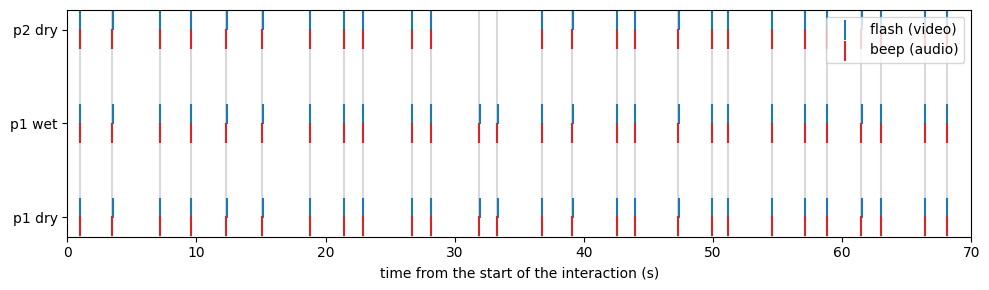

In [7]:
def flashes(video):
    raw = subprocess.run(["ffmpeg", "-v", "error", "-i", video, "-vf", "scale=8:6,format=gray", "-f", "rawvideo", "-"],
                         capture_output=True, check=True).stdout
    on = np.frombuffer(raw, np.uint8).reshape(-1, 48).mean(1) > 128
    return np.flatnonzero(on[1:] & ~on[:-1]) / 30 + 1 / 30

def beeps(wav):
    import soundfile as sf
    x, sr = sf.read(wav)
    x = np.abs(x if x.ndim == 1 else x.mean(1))
    env = x[:len(x) // 240 * 240].reshape(-1, 240).max(1) > 0.1
    return (np.flatnonzero(env[1:] & ~env[:-1]) + 1) * 240 / sr

fig, ax = plt.subplots(figsize=(10, 3))
for k, r in enumerate(m[m.status == "ok"].itertuples()):
    f = flashes(str(out / "trimed" / "1-p1p2" / r.output))
    b = beeps(str(out / "trimed" / "1-p1p2" / r.output).replace(".mp4", ".wav"))
    ax.scatter(f, [k + 0.1] * len(f), marker="|", s=200, color="tab:blue", label="flash (video)" if k == 0 else None)
    ax.scatter(b, [k - 0.1] * len(b), marker="|", s=200, color="tab:red", label="beep (audio)" if k == 0 else None)
    near = [min(abs(e - x) for x in f) for e in EVENTS if any(abs(e - x) < 0.5 for x in f)]
    print(f"{r.user} {r.manip}: {len(f)} flashes, {len(b)} beeps; largest flash error {max(near) * 1000:.0f} ms; "
          f"largest beep error {max(min(abs(e - x) for e in EVENTS) for x in b) * 1000:.0f} ms")
for e in EVENTS:
    ax.axvline(e, color="0.85", zorder=0)
ax.set_yticks(range(len(m[m.status == 'ok'])), [f"{r.user} {r.manip}" for r in m[m.status == "ok"].itertuples()])
ax.set_xlabel("time from the start of the interaction (s)"); ax.legend(loc="upper right"); ax.set_xlim(0, LENGTH)
plt.tight_layout()

The grey lines are the true event times. Every flash and every beep sits on them, within one frame (33 ms) for the video and a few ms for the audio.
- p2 has nothing during their gap (30–34 s).
- p1's wet video starts 1 s late. Its first second is black, not frozen, and its picture starts exactly with the first flash, at 1.0 s.

## 7. Parameters

`align.align_folder(source_folder, folder_tag, target_folder, ...)`:

| parameter | default | what it does |
|---|---|---|
| `source_folder` | | the `recordings/` folder of one interaction (ends with `/`) |
| `folder_tag` | | interaction name, used as the output sub-folder (ends with `/`) |
| `target_folder` | | root of the preprocessed data; outputs go to `<target_folder>/<trimed_path>/<folder_tag>` |
| `trimed_path` | `"trimed/"` | sub-folder of the outputs |
| `extension` | `".mp4"` | recordings to read (`.ogg` for audio-only experiments, with `video_out=False`) |
| `manips` | `("dry", "wet")` | versions to process |
| `log_folder` | parent of `source_folder` | where the `*.log` files are |
| `duration` | `None` | cap on the output length (s from t0) |
| `fps` | `30` | constant output frame rate |
| `crf` | `0` | x264 quality: `0` = lossless (analyses; ~200 MB per 4 min at 800x600), `18` = visually lossless and much smaller |
| `preset` | `"veryfast"` | x264 speed preset |
| `write_wav` | `True` | also write a lossless WAV next to each mp4 |
| `video_out` | `True` | `False`: WAV only |
| `sample_rate`, `audio_codec`, `audio_bitrate`, `wav_codec` | `48000`, `"aac"`, `"320k"`, `"pcm_s16le"` | audio of the outputs |
| `threads` | `0` | ffmpeg threads (0 = auto) |
| `overwrite` | `False` | re-render existing outputs (otherwise they are skipped, so a re-run resumes) |
| `av_sync` | `True` | measure each file's audio-video lag from its content, to verify / correct the offset seen in the durations. `False`: durations only (flagged *unverified*) |
| `av_check` | `True` | measure each rendered mp4 again (`av_check*` columns) |
| `max_offset` | `5.0` | larger offsets are reported, not applied |
| `mouth_backend` | `"auto"` | mouth signal of the sync measurement: `"mediapipe"` (jaw opening, best, ~100 s per 4-min file), `"opencv"` (lower-face motion, ~10 s, weaker), `"frame"` (whole-frame motion) |
| `face_model` | `None` | MediaPipe face landmarker model; or set `PREPRO_FACE_MODEL`, or put it in `models/face_landmarker.task` |
| `twin_sync` | `True` | align each wet file on its dry twin (video by image content; audio from the dry twin when there is no audio effect) |

`ducksoup.ds_process` and `ducksoup.ds_process_parallel` call `align_folder`, and can then combine the outputs into side-by-side check videos (`combine_videos`). Their main options are:
- `single_pass` (default `True`);
- `lossless` (default `True`) and `crf_single_pass` (used when `lossless=False`);
- `target_fps`, `duration`, `write_wav`, `ffmpeg_threads`;
- `av_sync`, which switches both the content measurement and the output check;
- `processes`, for `ds_process_parallel`.

`single_pass=False` runs the legacy three-encode chain, which has the alignment problems listed in section 1.

## 8. Running on real data

```python
from ducksoup import ds_process_parallel
ds_process_parallel(sources="original_data/<experiment>/<session>/*/recordings/",
                    target_folder="preproc/<experiment>/<session>/",
                    folder_tag_idx=-2,         # position of the interaction folder in the path
                    processes=8, ffmpeg_threads=2)
```

Or call `align.align_folder` directly for each interaction, e.g. in a Slurm array with one task per session.

**Time per 4-min recording**, with the MediaPipe backend:
- ~100 s to measure each dry file's sync;
- ~10 s for each wet twin comparison;
- ~100 s for each output check;
- plus the encode.

Without MediaPipe, OpenCV takes ~10 s per measurement but is weaker.

To use MediaPipe, run prepro in an environment that has `mediapipe` and set `PREPRO_FACE_MODEL=/path/to/face_landmarker.task`.

**After a run, look at:**
- outputs with `av_check == "mismatch"`;
- outputs whose `offset_source` is `duration` (unverified);
- the `notes` column;
- `status` values other than `ok`: `skipped_empty_file` (0-byte recordings), `skipped_before_t0`, `ffmpeg_error: …`.

## 9. Using the outputs in analyses

- **Time 0 is the start of the interaction**, for every output of the interaction. Frame `k` of any output is at `k / fps` s, and sample `n` of the WAV at `n / 48000` s. The partners are on the same clock, so you can compare them frame by frame.
- **Gaps** (reconnections, or a recording that starts late) are black frames and silence. **Mask them** using the segments of the manifest, rather than reading the filler as data:

In [8]:
def covered_mask(row, fps=30):
    # True for the frames of an output that come from a recording (False in gaps)
    n = int(round(row["duration_s"] * fps))
    mask = np.zeros(n, bool)
    for s in json.loads(row["segments"]):
        a, b = int(round(s["t_begin"] * fps)), int(round(s["t_end"] * fps))
        mask[a:b] = True
    return mask

p2 = next(r for r in manifest if r.get("user") == "p2")
mask = covered_mask(p2)
print(f"p2: {mask.sum() / 30:.1f} s recorded out of {len(mask) / 30:.1f} s; first gap frame at {np.argmin(mask) / 30:.2f} s")

p2: 66.0 s recorded out of 70.0 s; first gap frame at 30.00 s


- **Audio.** `audio_covered_s` < `covered_s` means a recording's audio stopped before its video, for example a dead microphone. Use the WAV for audio features.
- **Wet files.** These are what the partner saw. They are on the dry file's clock (`video_offset_s`). When there is no audio effect they carry the dry audio, so their audio is identical to the dry one.
- **Check the decisions.** `offset_source` and `notes` say how each audio offset was decided; `av_check` says whether the output was verified in sync.